# Generic multilayer perceptron (MLP) model

Trains an MLP on any dataset with categorical variables (3-10 categories) without knowing the specific variable names.

Target and ID columns are detected from candidate name lists (`var1`, `event_oneyear`, `target`, `outcome`, `y`, `label` for the target; `trr_id_code`, `id`, `patient_id`, `subject_id` for the ID), or named explicitly in the config. One-hot encoded categoricals are read as groups, with their reference columns chosen during preprocessing and reported below. Hyperparameters are set in the configuration cell.


## Setup and imports


In [1]:
%load_ext autoreload
%autoreload 2

# Set CPU fallback for MPS (Apple Silicon)
import os

os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'
print("PYTORCH_ENABLE_MPS_FALLBACK =", os.environ.get('PYTORCH_ENABLE_MPS_FALLBACK'))

import logging
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from prism.config import (
    CONFIG_NAME,
    DATASET_PREFIX,
    INTERIM_DATA_DIR,
    MODELS_DIR,
    PROCESSED_DATA_DIR,
    PROJ_ROOT,
)
from prism.config_loader import (
    DEFAULT_ID_CANDIDATES,
    DEFAULT_TARGET_CANDIDATES,
    detect_target_and_id_columns,
    load_config_if_exists,
)
from prism.logging_config import setup_logging

# =============================================================================
# DATASET CHECK - Ensure .env is configured
# =============================================================================
if DATASET_PREFIX is None:
    print("=" * 70)
    print("ERROR: No dataset configured!")
    print("=" * 70)
    print("\nPlease configure your dataset in the .env file:")
    print("  1. Copy .env.example to .env")
    print("  2. Set PRISM_CONFIG=your_config (loads example_notebooks/config/your_config.yaml)")
    print("     OR set PRISM_DATASET=your_dataset (quick mode, no YAML needed)")
    print("\nExample .env contents:")
    print("  PRISM_CONFIG=htx_example")
    print("=" * 70)
    raise ValueError("DATASET_PREFIX is None - configure .env file")

print(f"Dataset: {DATASET_PREFIX}")
if CONFIG_NAME:
    print(f"Config: {CONFIG_NAME}.yaml")
from prism.data_utilities import save_split_datasets
from prism.device_tools import get_device, get_num_cpu_workers
from prism.maskedmlp import train_mlp
from prism.metrics import evaluate_model_performance
from prism.preprocessing import PRiSMScaler, detect_reference_columns

PYTORCH_ENABLE_MPS_FALLBACK = 1


2026-03-19 18:02:39.598 | INFO     | prism.config:<module>:17 - PROJ_ROOT path is: C:\Users\user\PRiSM


2026-03-19 18:02:39.617 | INFO     | prism.config:<module>:73 - Config mode: CONFIG_NAME=credit-g_full, DATASET_PREFIX=credit-g


Dataset: credit-g
Config: credit-g_full.yaml


## Configuration


In [2]:
# ============================================================================
# CONFIGURATION
# ============================================================================
model_name = 'mlp'
DATA_PREFIX = DATASET_PREFIX  # from config.py

# Random seed for reproducibility
random_seed = 257

# ============================================================================
# TARGET AND ID VARIABLE CONFIGURATION (MANUAL DEFAULTS)
# ============================================================================
# These defaults are imported from prism.config_loader but can be overridden here.
# To customize, uncomment and modify the lines below:
# TARGET_CANDIDATES = ['my_target', 'outcome', 'label']
# ID_CANDIDATES = ['my_id', 'patient_id']
TARGET_CANDIDATES = list(DEFAULT_TARGET_CANDIDATES)  # Copy to allow modification
ID_CANDIDATES = list(DEFAULT_ID_CANDIDATES)  # Copy to allow modification

# ============================================================================
# LOAD CONFIG FILE (OVERRIDES MANUAL SETTINGS ABOVE)
# ============================================================================
# Use CONFIG_NAME if set (from .env PRISM_CONFIG), otherwise try DATA_PREFIX
config_to_load = CONFIG_NAME if CONFIG_NAME else DATA_PREFIX
config = load_config_if_exists(config_to_load)

if config:
    print(f"Config file found: {config_to_load}.yaml")
    if 'random_seed' in config:
        random_seed = config['random_seed']
        print(f"   [ok] random_seed: {random_seed}")
    if 'target_candidates' in config:
        TARGET_CANDIDATES = config['target_candidates']
        print(f"   [ok] target_candidates: {TARGET_CANDIDATES}")
    if 'id_candidates' in config:
        ID_CANDIDATES = config['id_candidates']
        print(f"   [ok] id_candidates: {ID_CANDIDATES}")
else:
    print("No config file found - using manual settings above")
    print("Edit the settings in the cells above if needed.")

# Apply random seed
np.random.seed(random_seed)
torch.manual_seed(random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed(random_seed)
    torch.cuda.manual_seed_all(random_seed)

# Device: 'device' in the YAML config or the PRISM_DEVICE env var overrides
# auto-detection ('auto', 'cpu', 'cuda', 'mps'); default is the best available
device = get_device(config.get('device') if config else None)
print(f"Using device: {device}")

# Check the data prefix that will be used to load train, test, and validation cohorts
print(f"DATA_PREFIX = '{DATA_PREFIX}'")
print(f"Will load data files from {INTERIM_DATA_DIR}:")

# Define filename variables
train_filename = f'{DATA_PREFIX}_train.csv'
test_filename = f'{DATA_PREFIX}_test.csv'
val_filename = f'{DATA_PREFIX}_val.csv'

print(f"  - {train_filename}")
print(f"  - {test_filename}")
print(f"  - {val_filename}")

model_identifier = f"{DATA_PREFIX}_{model_name}"
print(f"Model identifier: {model_identifier}")

# Set up logging (use logging.DEBUG for more detailed logs, logging.INFO for less detailed logs)
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
setup_logging(
    file_log_level=logging.INFO,
    log_file=f'model_{DATA_PREFIX}_{model_identifier}_{timestamp}.log',
    console_output=True,
    root_log_level=logging.WARNING,
)

Config file found: credit-g_full.yaml
   [ok] random_seed: 257
Using device: cuda
DATA_PREFIX = 'credit-g'
Will load data files from C:\Users\user\PRiSM\example_notebooks\pipeline_results\20260319_credit-g_full_4\data\interim:
  - credit-g_train.csv
  - credit-g_test.csv
  - credit-g_val.csv
Model identifier: credit-g_mlp
[2026-03-19 18:02:41] INFO [logging_config.py:73] - Logging setup complete. Logs will be saved to: C:\Users\user\PRiSM\logs\model_credit-g_credit-g_mlp_20260319_180241.log (console output enabled)


## Data loading and variable detection


In [3]:
# Load data
print("Loading data...")
# Skip comment lines that start with '#' to avoid header issues
data_train = pd.read_csv(INTERIM_DATA_DIR.joinpath(train_filename), comment='#')
data_test = pd.read_csv(INTERIM_DATA_DIR.joinpath(test_filename), comment='#')
data_val = pd.read_csv(INTERIM_DATA_DIR.joinpath(val_filename), comment='#')

print(f"Training data shape: {data_train.shape}")
print(f"Test data shape: {data_test.shape}")
print(f"Validation data shape: {data_val.shape}")

Loading data...
Training data shape: (600, 44)
Test data shape: (200, 44)
Validation data shape: (200, 44)


In [4]:
# Detect target and ID columns using the centralized function from prism.config_loader
target_column, id_column = detect_target_and_id_columns(
    data_train,
    target_candidates=TARGET_CANDIDATES,
    id_candidates=ID_CANDIDATES,
)

# Fallback detection if automatic detection fails
if target_column is None:
    print("\n" + "=" * 50)
    print("FALLBACK TARGET DETECTION")
    print("=" * 50)

    # Try to find binary columns that could be targets
    binary_cols = []
    for col in data_train.columns:
        unique_vals = sorted(data_train[col].dropna().unique())
        if len(unique_vals) == 2 and set(unique_vals) == {0, 1}:
            binary_cols.append(col)

    if binary_cols:
        target_column = binary_cols[0]  # Use first binary column
        print(f"Found binary columns: {binary_cols}")
        print(f"Using as target: {target_column}")
    else:
        # Last resort: use first column
        target_column = data_train.columns[0]
        print(f"No binary columns found. Using first column as target: {target_column}")

if id_column is None:
    print("\n" + "=" * 50)
    print("FALLBACK ID DETECTION")
    print("=" * 50)
    print("No ID column found. Will create synthetic IDs during data preparation.")

print(f"\nFinal detection results:")
print(f"  Target column: {target_column}")
print(f"  ID column: {id_column}")

Detecting target and ID columns...
  Available columns: ['duration', 'credit_amount', 'savings_status', 'employment', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents', 'own_telephone', 'foreign_worker', 'target', 'checking_status_<0', 'checking_status_>=200', 'checking_status_no checking', 'credit_history_critical/other existing credit', 'credit_history_delayed previously', 'credit_history_existing paid', 'credit_history_no credits/all paid', 'purpose_domestic appliance', 'purpose_education', 'purpose_furniture/equipment', 'purpose_new car', 'purpose_other', 'purpose_radio/tv', 'purpose_repairs', 'purpose_retraining', 'purpose_used car', 'personal_status_male div/sep', 'personal_status_male mar/wid', 'personal_status_male single', 'other_parties_guarantor', 'other_parties_none', 'property_magnitude_life insurance', 'property_magnitude_no known property', 'property_magnitude_real estate', 'other_payment_plans_none', 'other_payment_plans_stores', '

In [5]:
# Note: Reference columns are now dropped during preprocessing (drop_reference_columns=True)
# This cell shows reference column info from the config loaded earlier

if config:
    reference_column_strategy = config.get('reference_column_strategy', 'alphabetical')
    manual_reference_columns = config.get('reference_columns', None)

    print(f"Reference column strategy: {reference_column_strategy}")
    if manual_reference_columns:
        print(f"Reference columns (already dropped during preprocessing):")
        for group, ref_col in manual_reference_columns.items():
            print(f"  {group}: {ref_col}")
else:
    print("No config file - using default reference column detection")

print("\n" + "=" * 70)
print("NOTE: Reference columns have been dropped during preprocessing.")
print("All one-hot encoded groups now have N-1 columns (reference excluded).")
print("=" * 70)

Reference column strategy: alphabetical

NOTE: Reference columns have been dropped during preprocessing.
All one-hot encoded groups now have N-1 columns (reference excluded).


## Data preparation


In [6]:
# Prepare data for modeling
print("Preparing data for modeling...")

# If target column is not detected, try to find it manually
if target_column is None:
    print("\nWARNING: Target column not automatically detected!")
    print("Available columns:", list(data_train.columns))

    # Try to find the first column that looks like a target (binary 0/1)
    for col in data_train.columns:
        unique_vals = sorted(data_train[col].dropna().unique())
        if len(unique_vals) == 2 and set(unique_vals) == {0, 1}:
            target_column = col
            print(f"  Found potential target column: {col} with values {unique_vals}")
            break

    if target_column is None:
        # If still not found, use the first column as target
        target_column = data_train.columns[0]
        print(f"  Using first column as target: {target_column}")
        print(f"  Values: {sorted(data_train[target_column].dropna().unique())}")

# If ID column is not detected, create a synthetic one
if id_column is None:
    print("\nWARNING: ID column not automatically detected!")
    id_column = 'trr_id_code'
    print(f"  Creating synthetic ID column: {id_column}")

    # Add synthetic IDs to all datasets
    for i, df in enumerate([data_train, data_test, data_val]):
        df[id_column] = [f"B{j:06d}" for j in range(len(df))]
    print(f"  Added synthetic IDs to all datasets")

# Define columns to drop (just target and ID - reference columns already dropped)
drop_cols = [target_column, id_column]

print(f"\nColumns to drop:")
print(f"  Target: {target_column}")
print(f"  ID: {id_column}")
print(f"  (Reference columns were already dropped during preprocessing)")

# Prepare feature matrices
X_train = data_train.drop(drop_cols, axis=1)
y_train = data_train[target_column]

X_test = data_test.drop(drop_cols, axis=1)
y_test = data_test[target_column]

print(f"\nFeature matrices prepared:")
print(f"  Training: {X_train.shape}")
print(f"  Test: {X_test.shape}")

# Get feature names (as in original notebook)
feature_names = X_train.columns.tolist()

# Check class distribution
print(f"\nClass distribution in training set:")
print(y_train.value_counts(normalize=True))

print(f"\nClass distribution in test set:")
print(y_test.value_counts(normalize=True))

Preparing data for modeling...



Columns to drop:
  Target: target
  ID: trr_id_code
  (Reference columns were already dropped during preprocessing)

Feature matrices prepared:
  Training: (600, 42)
  Test: (200, 42)

Class distribution in training set:
target
1    0.7
0    0.3
Name: proportion, dtype: float64

Class distribution in test set:
target
1    0.7
0    0.3
Name: proportion, dtype: float64


## Data scaling and preprocessing


In [7]:
# Create and fit PRiSMScaler on training data
# PRiSMScaler uses MedianStdScaler with sd_scale=2.0 by default
scaler = PRiSMScaler(scaler='median_std')
scaler.fit(X_train)

# Transform data and convert to tensors using to_tensor method
X_train_tensor = scaler.to_tensor(X_train, device=device)
X_test_tensor = scaler.to_tensor(X_test, device=device)

# Convert target variables to tensors
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32, device=device)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32, device=device)

print(f"Scaler type: {type(scaler).__name__}")
print(f"Underlying scaler: {type(scaler.scaler).__name__}")
print(f"Training data shape: {X_train_tensor.shape}")
print(f"Training tensor device: {X_train_tensor.device}")

[2026-03-19 18:02:41] INFO [preprocessing.py:242] - Auto-detected 33 binary columns to exclude from scaling


Scaler type: PRiSMScaler
Underlying scaler: MedianStdScaler
Training data shape: torch.Size([600, 42])
Training tensor device: cuda:0


## Hyperparameter tuning (optional)

Hyperparameters are determined in this order:
1. If `hyperparameter_tuning.mlp.params_file` is specified -> load from that file
2. If `hyperparameter_tuning.mlp.enabled: true` -> run Optuna tuning now
3. If `hyperparameter_tuning.skip_saved_params: true` -> use the hardcoded defaults
4. If a best_params file exists in MODELS_DIR -> load from there
5. Otherwise -> use the hardcoded defaults

The `--no-tune` flag (which sets the `PRISM_NO_TUNE` environment variable) skips inline tuning.

In [8]:
# Hyperparameter tuning or loading
import os

from prism.config_loader import get_tuning_config
from prism.hyperparameter_tuning import (
    load_best_params,
    load_params_from_file,
    load_tuned_model,
    run_hyperparameter_tuning,
    save_best_model,
    save_best_params,
)

# Get tuning config
tuning_config = get_tuning_config(config, 'mlp')

# Check if tuning should be skipped via environment variable (set by --no-tune flag)
no_tune = os.environ.get('PRISM_NO_TUNE', '').lower() in ('1', 'true', 'yes')

tuned_params = None
best_tuned_model = None  # Track best model from tuning
if hasattr(tuning_config, 'params_file') and tuning_config.params_file:
    # Option 1: Explicit params_file specified in config
    print(f"Loading parameters from config-specified file: {tuning_config.params_file}")
    tuned_params = load_params_from_file(tuning_config.params_file)
elif tuning_config.enabled and not no_tune:
    # Option 2: Run hyperparameter tuning now
    print(f"Running MLP hyperparameter tuning ({tuning_config.n_trials} trials)...")
    tuned_params, study, best_tuned_model = run_hyperparameter_tuning(
        model_type='mlp',
        X_train=X_train_tensor,
        y_train=y_train_tensor,
        X_test=X_test_tensor,
        y_test=y_test_tensor,
        tuning_config=tuning_config,
        random_seed=random_seed,
        device=str(device),
    )
    # Save the results
    save_best_params(tuned_params, 'mlp', DATA_PREFIX, MODELS_DIR, study)
    print(f"Tuning complete. Best AUC: {study.best_value:.4f}")
    print(f"Best params saved to {MODELS_DIR}")
    # Save the best model from tuning
    if best_tuned_model is not None:
        save_best_model(
            model=best_tuned_model,
            model_type='mlp',
            dataset_prefix=model_identifier,
            output_dir=MODELS_DIR,
            scaler=scaler,
            hyperparameters=tuned_params,
            feature_names=feature_names,
        )
        print(f"Best tuned model saved to {MODELS_DIR / model_identifier}")
elif getattr(tuning_config, 'skip_saved_params', False):
    # Option 3a: skip_saved_params=True -> use defaults only
    print("skip_saved_params=True, using default hyperparameters.")
else:
    # Option 3b: Try to find existing params in MODELS_DIR
    tuned_params = load_best_params('mlp', DATA_PREFIX, MODELS_DIR)
    if tuned_params:
        print(f"Loaded existing tuned params from {MODELS_DIR}")

if tuned_params:
    print("Using hyperparameters:")
    for key, value in tuned_params.items():
        print(f"  {key}: {value}")
else:
    print("No tuned hyperparameters found. Using defaults.")

[2026-03-19 18:02:42] INFO [config_loader.py:511] - Using global tuning config for mlp


Running MLP hyperparameter tuning (128 trials)...
[2026-03-19 18:02:42] INFO [tuning.py:397] - Auto-enabling multiprocessing for safe GPU parallelization (PyTorch model)


[2026-03-19 18:02:42] INFO [tuning.py:399] - Starting hyperparameter tuning for mlp


[2026-03-19 18:02:42] INFO [tuning.py:400] -   n_trials: 128


[2026-03-19 18:02:42] INFO [tuning.py:401] -   metric: test_auc


...

[I 2026-03-19 18:04:33,557] Trial 0 finished with value: 0.8227380952380954 and parameters: {'n_hidden': 39, 'lr': 0.0009192976614316049, 'weight_decay': 3.984918807132233e-05, 'patience': 12, 'batch_size': 1024}. Best is trial 0 with value: 0.8227380952380954.


[2026-03-19 18:04:35] WARNING [tuning.py:172] - Could not clean up temp directory C:\Users\user~1\AppData\Local\Temp\optuna_mp_nd6asdl0: [WinError 32] The process cannot access the file because it is being used by another process: 'C:\\Users\\LOCALU~1\\AppData\\Local\\Temp\\optuna_mp_nd6asdl0\\optuna_study.db'. The directory will be cleaned up by the OS later.


[2026-03-19 18:04:35] INFO [tuning.py:556] - Saved best parameters to C:\Users\user\PRiSM\example_notebooks\pipeline_results\20260319_credit-g_full_4\mlp\models\credit-g_mlp_best_params.json


Tuning complete. Best AUC: 0.8227
Best params saved to C:\Users\user\PRiSM\example_notebooks\pipeline_results\20260319_credit-g_full_4\mlp\models
[2026-03-19 18:04:35] INFO [tuning.py:630] - Saved best tuned model to C:\Users\user\PRiSM\example_notebooks\pipeline_results\20260319_credit-g_full_4\mlp\models\credit-g_mlp\credit-g_mlp_model_tuned.pt


Best tuned model saved to C:\Users\user\PRiSM\example_notebooks\pipeline_results\20260319_credit-g_full_4\mlp\models\credit-g_mlp
Using hyperparameters:
  n_hidden: 39
  lr: 0.0009192976614316049
  weight_decay: 3.984918807132233e-05
  patience: 12
  batch_size: 1024


## Model training


In [9]:
# Check if a tuned model already exists (skip training if so)
tuned_model_checkpoint = load_tuned_model('mlp', model_identifier, MODELS_DIR)
model = None

if tuned_model_checkpoint is not None:
    print(f"Found tuned model - loading instead of retraining...")
    model = tuned_model_checkpoint['model']
    # Use hyperparameters from the tuned model
    mlp_hyperparameters = tuned_model_checkpoint.get('hyperparameters', {})
    print(f"Loaded tuned model: {type(model).__name__}")
    print(f"Hyperparameters from tuned model: {mlp_hyperparameters}")
else:
    # MLP hyperparameters - use tuned params if available, else htx_example demo defaults
    mlp_hyperparameters = {
        'n_hidden': tuned_params.get('n_hidden', 36) if tuned_params else 36,
        'mask': None,
        'weight_decay': tuned_params.get('weight_decay', 6e-5) if tuned_params else 6e-5,
        'lr': tuned_params.get('lr', 0.0014) if tuned_params else 0.0014,
        'tolerance': 0.0001,
        'patience': tuned_params.get('patience', 16) if tuned_params else 16,
        'max_iter': 4000,
        'batch_size': tuned_params.get('batch_size', 512) if tuned_params else 512,
        'scale_lr': False,  # Do not scale LR - use tuned LR directly
        'device': str(device),
        'seed': random_seed,
        'plot_loss': True,
        'plot_update_epochs': 10,
    }

    print("MLP Hyperparameters:")
    print("=" * 40)
    for key, value in mlp_hyperparameters.items():
        print(f"{key}: {value}")

    print(f"\nInput features: {X_train_tensor.shape[1]}")
    print(f"Hidden units: {mlp_hyperparameters['n_hidden']}")
    print(f"Output size: 1 (binary classification)")

    # Train the model
    print("\nStarting MLP training...")
    model = train_mlp(X_train_tensor, y_train, X_test_tensor, y_test, **mlp_hyperparameters)

print(f"Model type: {type(model).__name__}")

[2026-03-19 18:04:35] INFO [tuning.py:661] - Loading tuned model from C:\Users\user\PRiSM\example_notebooks\pipeline_results\20260319_credit-g_full_4\mlp\models\credit-g_mlp\credit-g_mlp_model_tuned.pt


Found tuned model - loading instead of retraining...
Loaded tuned model: MaskedMLP
Hyperparameters from tuned model: {'n_hidden': 39, 'lr': 0.0009192976614316049, 'weight_decay': 3.984918807132233e-05, 'patience': 12, 'batch_size': 1024}
Model type: MaskedMLP


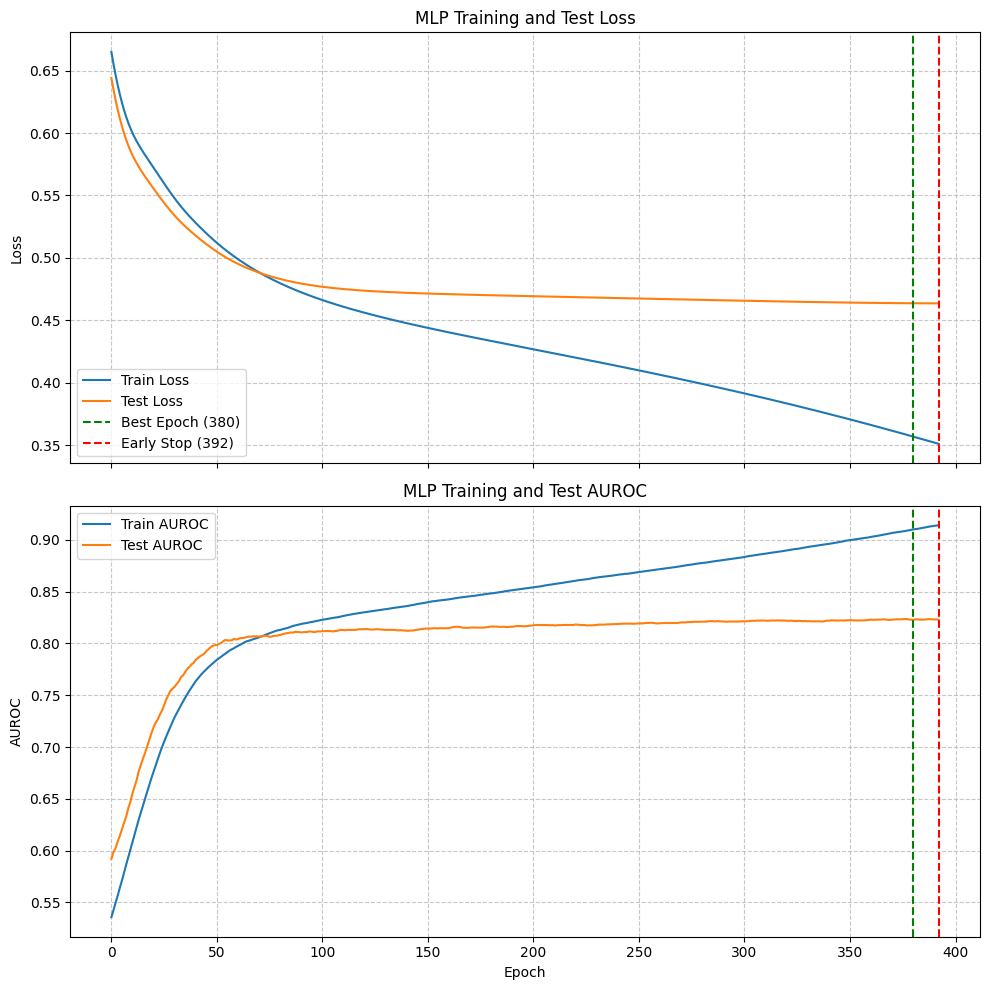

True

In [10]:
# Plot training history (from tuned model checkpoint or from training)
from prism.notebook_utils import get_training_history, plot_training_history

training_history = get_training_history(model, tuned_model_checkpoint)
plot_training_history(training_history, title_prefix='MLP')

In [11]:
training_results = {
    'model': model,
    'scaler': scaler,
    'feature_names': feature_names,
    'target_column': target_column,
    'epochs_trained': mlp_hyperparameters.get('max_iter', 'tuned'),
}

## Model evaluation


Evaluating model performance...
Evaluating on training set...

---- Model Performance Metrics mlp - Training Data ----
Threshold (prevalence) set to: 0.700
AUROC:		0.914 (95% CI: 0.900-0.933) (Area Under the Receiver Operating Characteristic curve)
Accuracy:	0.828 (Proportion of correct predictions)
Precision:	0.930 (Proportion of true positives among positive predictions, aka PPV)
Recall:		0.817 (Proportion of true positives among actual positives, aka sensitivity)
F1 Score:	0.869 (Harmonic mean of precision and recall)
--------------------------------------------


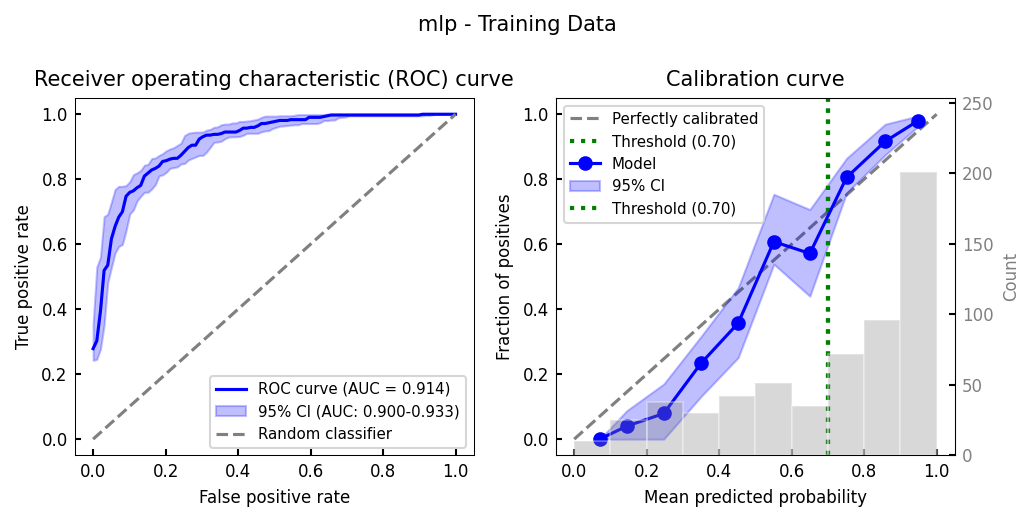

Evaluating on test set...

---- Model Performance Metrics mlp - Test Data ----
Threshold (prevalence) set to: 0.700
AUROC:		0.823 (95% CI: 0.777-0.864) (Area Under the Receiver Operating Characteristic curve)
Accuracy:	0.800 (Proportion of correct predictions)
Precision:	0.885 (Proportion of true positives among positive predictions, aka PPV)
Recall:		0.821 (Proportion of true positives among actual positives, aka sensitivity)
F1 Score:	0.852 (Harmonic mean of precision and recall)
--------------------------------------------


C:\Users\user\PRiSM\prism\metrics.py:820: UserWarning: mlp - Test Data: Skipped confidence intervals for 1 bin(s) due to insufficient samples (threshold: 5). Bin indices: [0]. These bins had the following sample counts: [4.].
  warnings.warn(


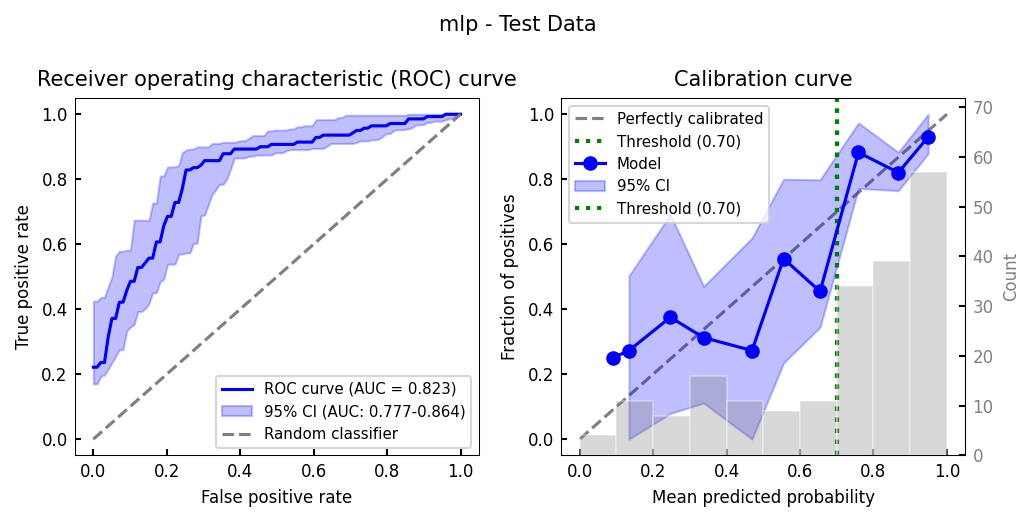


Model Performance Summary:
Training - AUROC: 0.9140, Accuracy: 0.8283
Test     - AUROC: 0.8227, Accuracy: 0.8000


In [12]:
# Evaluate model performance
print("Evaluating model performance...")

# Training set evaluation
print("Evaluating on training set...")
y_pred_train = model.predict_proba(X_train_tensor)
train_metrics = evaluate_model_performance(
    y_train_tensor,
    y_pred_train,
    y_train_tensor,
    title=f"{model_name} - Training Data",
    random_seed=random_seed,
)

# Test set evaluation
print("Evaluating on test set...")
y_pred_test = model.predict_proba(X_test_tensor)
test_metrics = evaluate_model_performance(
    y_test,
    y_pred_test,
    y_train,
    title=f"{model_name} - Test Data",
    random_seed=random_seed,
)

print("\nModel Performance Summary:")
print("=" * 50)
print(f"Training - AUROC: {train_metrics['auroc']:.4f}, Accuracy: {train_metrics['accuracy']:.4f}")
print(f"Test     - AUROC: {test_metrics['auroc']:.4f}, Accuracy: {test_metrics['accuracy']:.4f}")

## Model saving


In [13]:
# Save the model and scaler
print("Saving model and scaler...")

# Create model directory
model_dir = MODELS_DIR / model_identifier
model_dir.mkdir(parents=True, exist_ok=True)

# Generate timestamp for model filename
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
model_filename = f"{model_identifier}_model_{timestamp}.pt"

# Save model checkpoint
model_path = model_dir / model_filename

# Save the model in PyTorch standard format
torch.save(
    {
        'scaler': scaler,  # Save the scaler with the model
        'model': model,  # Full model for convenience
        'model_state_dict': model.state_dict(),
        'model_class': type(model),
        'hyperparameters': mlp_hyperparameters,
        'feature_names': feature_names,
        'train_metrics': train_metrics,
        'test_metrics': test_metrics,
    },
    model_path,
)

print(f"Model saved to: {model_path}")
print(f"Model directory: {model_dir}")

Saving model and scaler...
Model saved to: C:\Users\user\PRiSM\example_notebooks\pipeline_results\20260319_credit-g_full_4\mlp\models\credit-g_mlp\credit-g_mlp_model_20260319_180437.pt
Model directory: C:\Users\user\PRiSM\example_notebooks\pipeline_results\20260319_credit-g_full_4\mlp\models\credit-g_mlp


In [14]:

# Save processed data to PROCESSED_DATA_DIR
# Note: Reference columns have already been dropped during preprocessing
print("\nSaving processed data...")

save_split_datasets(
    train_df=data_train,
    test_df=data_test,
    val_df=data_val,
    base_filename=model_identifier,
    save_dir=PROCESSED_DATA_DIR,
    include_timestamp=True,
    header_comment=f"target: {target_column}, patient IDs: {id_column}. All other features are model inputs, pre-normalization. Reference columns were dropped during preprocessing.",
)

print("Processed data saved successfully.")


Saving processed data...


Saved train dataset (600 samples) to: C:\Users\user\PRiSM\example_notebooks\pipeline_results\20260319_credit-g_full_4\data\processed\credit-g_mlp_20260319_180437_train.csv
Saved test dataset (200 samples) to: C:\Users\user\PRiSM\example_notebooks\pipeline_results\20260319_credit-g_full_4\data\processed\credit-g_mlp_20260319_180437_test.csv
Saved validation dataset (200 samples) to: C:\Users\user\PRiSM\example_notebooks\pipeline_results\20260319_credit-g_full_4\data\processed\credit-g_mlp_20260319_180437_val.csv
Processed data saved successfully.


In [15]:
print(f"\n" + "=" * 60)
print("MODEL TRAINING COMPLETE")
print("=" * 60)
print(f"Model identifier: {model_identifier}")
print(f"Model saved to: {model_path}")
print(f"Processed data saved to: {PROCESSED_DATA_DIR}")
print(f"Final test AUROC: {test_metrics['auroc']:.4f}")
print(f"Final test accuracy: {test_metrics['accuracy']:.4f}")
print(f"Features used: {len(feature_names)}")
print(f"Target variable: {target_column}")
print(f"ID variable: {id_column}")


MODEL TRAINING COMPLETE
Model identifier: credit-g_mlp
Model saved to: C:\Users\user\PRiSM\example_notebooks\pipeline_results\20260319_credit-g_full_4\mlp\models\credit-g_mlp\credit-g_mlp_model_20260319_180437.pt
Processed data saved to: C:\Users\user\PRiSM\example_notebooks\pipeline_results\20260319_credit-g_full_4\data\processed
Final test AUROC: 0.8227
Final test accuracy: 0.8000
Features used: 42
Target variable: target
ID variable: trr_id_code
